<a href="https://colab.research.google.com/github/Angel04-10/Churn-Prediction/blob/main/Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#for prediction
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries installed!")

✅ Libraries installed!


In [ ]:
import io
#import random
#from datetime import datetime, timedelta

#set seed so that you get exact output everytime this script is run
#np.random.seed(42)
#random.seed(42)

📊 Generating dataset (4,500 customers)...


In [ ]:
import random
from datetime import datetime, timedelta

#set seed so that you get exact output everytime this script is run
np.random.seed(42)
random.seed(42)

print("📊 Generating dataset (4,500 customers)...\n")

n_customers = 4500
reference_date = datetime(2024, 9, 15)
data = []

for i in range(n_customers):
    customer_id = f"C{1000 + i}"
    age = int(np.clip(np.random.normal(loc=32, scale=10), 18, 65))
    gender = np.random.choice(['Female', 'Male'], p=[0.55, 0.45])
    location = np.random.choice( ['Mumbai', 'Delhi', 'Bangalore', 'Hyderabad', 'Pune', 'Chennai', 'Kolkata', 'Ahmedabad', 'Jaipur', 'Lucknow'], p=[0.15, 0.12, 0.14, 0.11, 0.10, 0.09, 0.08, 0.07, 0.07, 0.07])
    metro = 1 if location in ['Mumbai', 'Delhi', 'Bangalore'] else 0
    account_age_months = int(np.clip(np.random.exponential(scale=15), 1, 60))

    days_since_purchase = int(np.abs(np.random.normal(loc=45, scale=40)))
    days_since_purchase = min(days_since_purchase, 180)
    last_purchase_date = reference_date - timedelta(days=days_since_purchase)

    purchase_frequency = np.random.normal(loc=2.5, scale=1.0)
    purchase_frequency = max(0.5, purchase_frequency)

    avg_purchase_amount = max(500, np.random.normal(loc=2500, scale=1200))
    return_frequency = np.random.uniform(0, 0.4)
    review_rating = max(1.0, min(5.0, np.random.normal(loc=4.0, scale=0.7)))

    cs_interactions = np.random.poisson(lam=2)
    subscription = np.random.choice(['Premium', 'Regular', 'None'], p=[0.25, 0.40, 0.35])
    has_subscription = 1 if subscription != 'None' else 0

    discount_sensitivity = np.random.uniform(0, 1)
    days_since_discount = int(np.random.exponential(scale=30))
    is_mobile_app = np.random.choice([1, 0], p=[0.65, 0.35])
    category_preference = np.random.choice(['Fashion', 'Electronics', 'Home', 'Beauty', 'Sports'], p=[0.40, 0.25, 0.15, 0.12, 0.08])

    # Calculate churn probability based on multiple factors
    churn_probability = 0.0

    # Base probability from recency
    if days_since_purchase > 90:
        churn_probability += 0.70
    elif days_since_purchase > 60:
        churn_probability += 0.50
    else:
        churn_probability += 0.15

    # Adjust based on returns (dissatisfaction signal)
    churn_probability += return_frequency * 0.3

    # Adjust based on subscription (loyalty signal)
    if has_subscription:
        churn_probability *= 0.5  # Cut churn risk in half

    # Adjust based on satisfaction
    if review_rating >= 4.5:
        churn_probability *= 0.6
    elif review_rating < 2.5:
        churn_probability *= 1.3

    # Clamp between 0 and 1
    churn_probability = max(0, min(1, churn_probability))

    # Convert to binary
    churn = 1 if np.random.random() < churn_probability else 0

    data.append({
        'CustomerID': customer_id,
        'Age': age,
        'Gender': gender,
        'Location': location,
        'Metro': metro,
        'Account_Age_Months': account_age_months,
        'Last_Purchase_Date': last_purchase_date.strftime('%Y-%m-%d'),
        'Days_Since_Purchase': days_since_purchase,
        'Purchase_Frequency_Per_Month': round(purchase_frequency, 2),
        'Avg_Purchase_Amount_INR': round(avg_purchase_amount, 2),
        'Return_Frequency': round(return_frequency, 3),
        'Review_Rating': round(review_rating, 2),
        'Customer_Service_Interactions': cs_interactions,
        'Subscription_Status': subscription,
        'Has_Subscription': has_subscription,
        'Discount_Sensitivity': round(discount_sensitivity, 2),
        'Days_Since_Last_Discount': days_since_discount,
        'Mobile_App_User': is_mobile_app,
        'Category_Preference': category_preference,
        'Churn': churn
    })

df = pd.DataFrame(data)

print("✅ Dataset created!")
print(f"Shape: {df.shape}")
print(f"Churn rate: {df['Churn'].mean():.2%}")

📊 Generating dataset (4,500 customers)...

✅ Dataset created!
Shape: (4500, 20)
Churn rate: 21.29%


In [ ]:
print(f"Length of data list: {len(data)}")
print(f"DataFrame shape: {df.shape}")
print(data[:2])  # Show first 2 items in data list

Length of data list: 4500
DataFrame shape: (4500, 20)
[{'CustomerID': 'C1000', 'Age': 36, 'Gender': np.str_('Male'), 'Location': np.str_('Pune'), 'Metro': 0, 'Account_Age_Months': 2, 'Last_Purchase_Date': '2024-08-07', 'Days_Since_Purchase': 39, 'Purchase_Frequency_Per_Month': 2.78, 'Avg_Purchase_Amount_INR': 3712.62, 'Return_Frequency': 0.283, 'Review_Rating': 3.67, 'Customer_Service_Interactions': 1, 'Subscription_Status': np.str_('Regular'), 'Has_Subscription': 1, 'Discount_Sensitivity': 0.52, 'Days_Since_Last_Discount': 16, 'Mobile_App_User': np.int64(1), 'Category_Preference': np.str_('Electronics'), 'Churn': 0}, {'CustomerID': 'C1001', 'Age': 37, 'Gender': np.str_('Female'), 'Location': np.str_('Bangalore'), 'Metro': 1, 'Account_Age_Months': 9, 'Last_Purchase_Date': '2024-08-27', 'Days_Since_Purchase': 19, 'Purchase_Frequency_Per_Month': 3.1, 'Avg_Purchase_Amount_INR': 5571.39, 'Return_Frequency': 0.019, 'Review_Rating': 4.28, 'Customer_Service_Interactions': 1, 'Subscription_Sta

# Data Inspection

In [ ]:
print("\n📋 DATA OVERVIEW")
print("="*80)

print(f"\n📊 Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\n🎯 Churn distribution:")
print(df['Churn'].value_counts())
print(f"\nChurn rate: {df['Churn'].mean():.2%}")

print(f"\n👤 Demographics:")
print(f"   Age range: {df['Age'].min()}-{df['Age'].max()} (mean: {df['Age'].mean():.1f})")
print(f"   Gender: {(df['Gender']=='Female').sum()} Female, {(df['Gender']=='Male').sum()} Male")
print(f"   Metro: {df['Metro'].sum()} ({df['Metro'].mean():.1%})")

print(f"\n💰 Purchase behavior:")
print(f"   Avg frequency: {df['Purchase_Frequency_Per_Month'].mean():.2f} purchases/month")
print(f"   Avg amount: ₹{df['Avg_Purchase_Amount_INR'].mean():.0f}")
print(f"   Days since purchase: {df['Days_Since_Purchase'].mean():.0f} (range: 0-{df['Days_Since_Purchase'].max()})")

print(f"\n📈 Engagement:")
print(f"   Subscription rate: {df['Has_Subscription'].mean():.1%}")
print(f"   Mobile app users: {df['Mobile_App_User'].mean():.1%}")
print(f"   Avg return rate: {df['Return_Frequency'].mean():.1%}")

print(f"\nFirst 5 rows:")
df.head()


📋 DATA OVERVIEW

📊 Dataset shape: 4500 rows × 20 columns

🎯 Churn distribution:
Churn
0    3542
1     958
Name: count, dtype: int64

Churn rate: 21.29%

👤 Demographics:
   Age range: 18-65 (mean: 31.9)
   Gender: 2478 Female, 2022 Male
   Metro: 1834 (40.8%)

💰 Purchase behavior:
   Avg frequency: 2.54 purchases/month
   Avg amount: ₹2507
   Days since purchase: 50 (range: 0-180)

📈 Engagement:
   Subscription rate: 65.3%
   Mobile app users: 64.8%
   Avg return rate: 19.9%

First 5 rows:


,CustomerID,Age,Gender,Location,Metro,Account_Age_Months,Last_Purchase_Date,Days_Since_Purchase,Purchase_Frequency_Per_Month,Avg_Purchase_Amount_INR,Return_Frequency,Review_Rating,Customer_Service_Interactions,Subscription_Status,Has_Subscription,Discount_Sensitivity,Days_Since_Last_Discount,Mobile_App_User,Category_Preference,Churn
0,C1000,36,Male,Pune,0,2,2024-08-07,39,2.78,3712.62,0.283,3.67,1,Regular,1,0.52,16,1,Electronics,0
1,C1001,37,Female,Bangalore,1,9,2024-08-27,19,3.10,5571.39,0.019,4.28,1,Premium,1,0.95,101,0,Fashion,0
2,C1002,25,Female,Hyderabad,0,1,2024-05-19,119,2.27,2967.22,0.265,4.15,1,None,0,0.78,84,0,Electronics,0
3,C1003,18,Female,Delhi,1,1,2024-09-11,4,0.92,3428.44,0.143,3.62,2,None,0,0.07,130,0,Fashion,1
4,C1004,37,Male,Kolkata,0,1,2024-06-27,80,1.66,2128.95,0.345,2.94,0,Regular,1,0.33,39,1,Beauty,0


# Data Visualization

Days Since Purchase (DSP) vs Churn

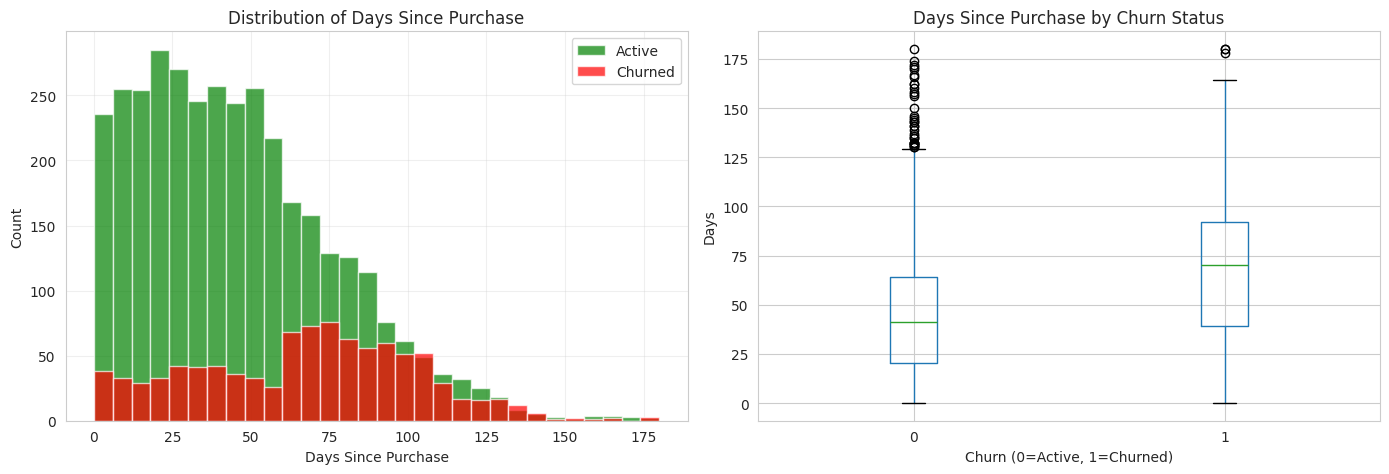


💡 Key finding:
   Active customers: 45 days avg
   Churned customers: 67 days avg
   Customers inactive 60+ days are likely churned!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Histogram
axes[0].hist(df[df['Churn']==0]['Days_Since_Purchase'], bins=30, label='Active', alpha=0.7, color='green')
axes[0].hist(df[df['Churn']==1]['Days_Since_Purchase'], bins=30, label='Churned', alpha=0.7, color='red')
axes[0].set_xlabel('Days Since Purchase')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Days Since Purchase')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

#Boxplot
df.boxplot(column='Days_Since_Purchase', by='Churn', ax=axes[1])
axes[1].set_title('Days Since Purchase by Churn Status')
axes[1].set_xlabel('Churn (0=Active, 1=Churned)')
axes[1].set_ylabel('Days')
plt.suptitle('')  # Remove automatic title
plt.tight_layout()
plt.show()

print(f"\n💡 Key finding:")
print(f"   Active customers: {df[df['Churn']==0]['Days_Since_Purchase'].mean():.0f} days avg")
print(f"   Churned customers: {df[df['Churn']==1]['Days_Since_Purchase'].mean():.0f} days avg")
print(f"   Customers inactive 60+ days are likely churned!")

Return Frequency and subscription Impact on Churn

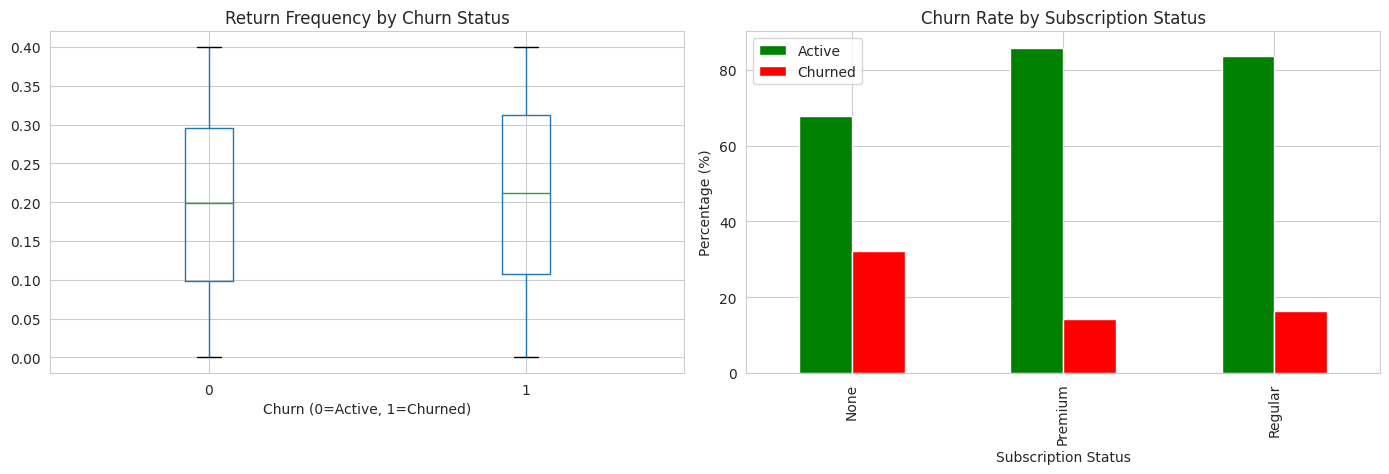

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Return frequency
df.boxplot(column='Return_Frequency', by='Churn', ax=axes[0])
axes[0].set_title('Return Frequency by Churn Status')
axes[0].set_xlabel('Churn (0=Active, 1=Churned)')

# Subscription impact
subscription_churn = pd.crosstab(df['Subscription_Status'], df['Churn'], normalize='index') * 100
subscription_churn.plot(kind='bar', ax=axes[1], color=['green', 'red'])
axes[1].set_title('Churn Rate by Subscription Status')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('Subscription Status')
axes[1].legend(['Active', 'Churned'])
plt.suptitle('')
plt.tight_layout()
plt.show()

In [ ]:
print(f"   Active customers return: {df[df['Churn']==0]['Return_Frequency'].mean():.1%}")
print(f"   Churned customers return: {df[df['Churn']==1]['Return_Frequency'].mean():.1%}")
print(f"   High returns predict churn!")
print(f"\n   Subscription impact on churn:")
print(subscription_churn)

   Active customers return: 19.7%
   Churned customers return: 20.8%
   High returns predict churn!

   Subscription impact on churn:
Churn                        0          1
Subscription_Status                      
None                 67.692308  32.307692
Premium              85.853227  14.146773
Regular              83.747927  16.252073


From above bar plot, it shows that users who have premium subscription are churned 18.16% less than generic users.

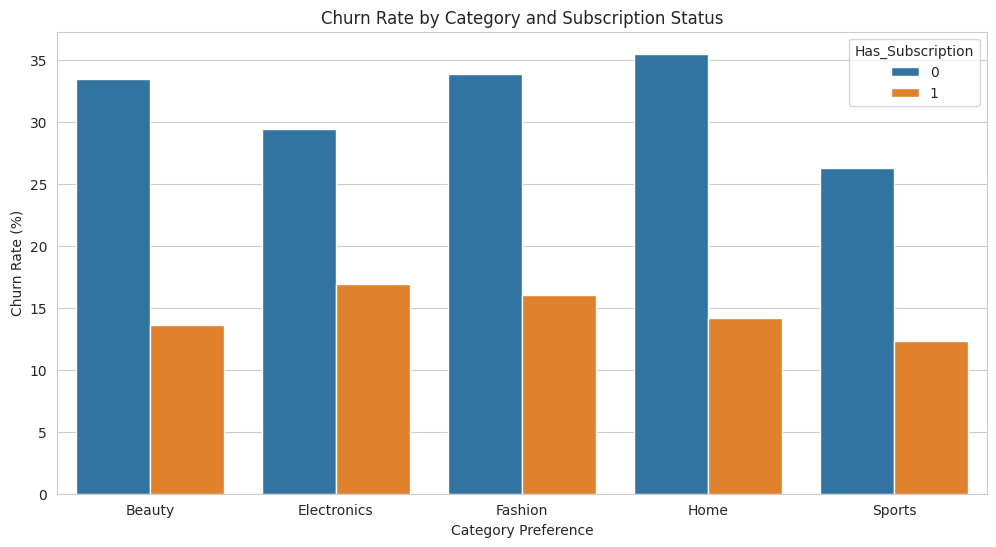

In [ ]:
#Plotting stacked bar plot to know from which category purchase is being made frequently
churn_analysis = (df.groupby(['Category_Preference', 'Has_Subscription'])['Churn'].mean().reset_index())
churn_analysis['Churn_Rate'] = churn_analysis['Churn'] * 100

sns.barplot(
    data=churn_analysis,
    x='Category_Preference',
    y='Churn_Rate',
    hue='Has_Subscription'
)

plt.ylabel('Churn Rate (%)')
plt.xlabel('Category Preference')
plt.title('Churn Rate by Category and Subscription Status')
plt.show()

Home category out of all have highest churn rate but all the other categories does not seem to affect churn rate of customers.

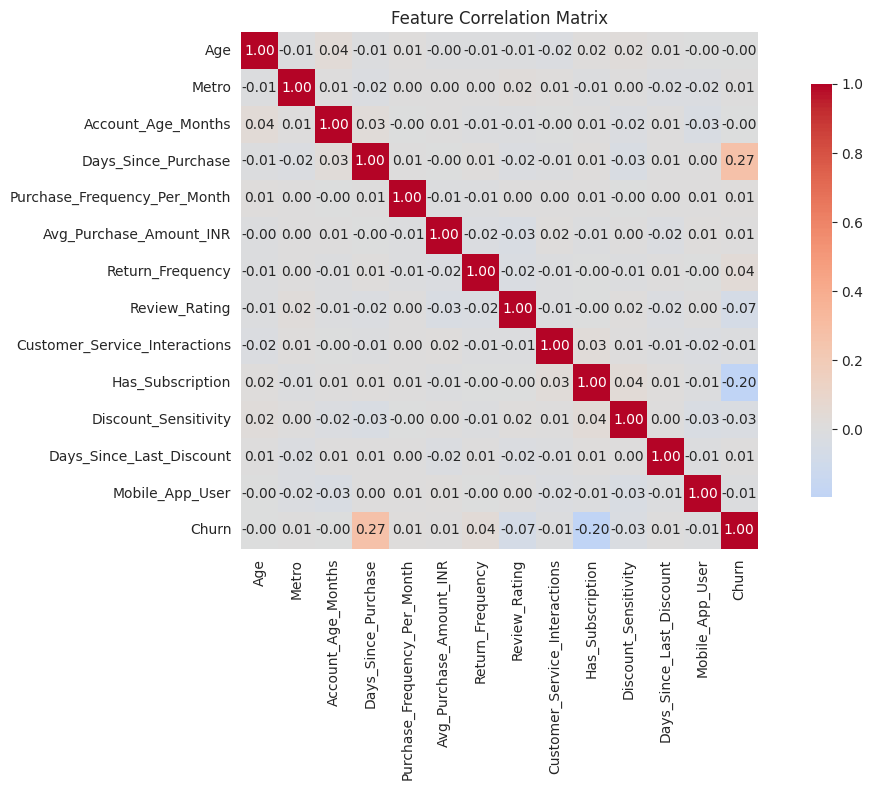


Top 10 features correlated with Churn:
Churn                           1.000000
Days_Since_Purchase             0.270473
Return_Frequency                0.040623
Purchase_Frequency_Per_Month    0.011321
Avg_Purchase_Amount_INR         0.008806
Days_Since_Last_Discount        0.008108
Metro                           0.006145
Age                            -0.000239
Account_Age_Months             -0.002705
Mobile_App_User                -0.007711
Name: Churn, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

print(f"\nTop 10 features correlated with Churn:")
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print(churn_corr.head(10))

Trying to see relation between two features having strongest relation with Churn, if they are dependent on each other. As expected, users having a subscription have less gaps between days since last purchase that is users are more frequently purchasing

In [ ]:
print("Correlation between DSP and Has_Subscription:")
print(df[['Days_Since_Purchase', 'Has_Subscription']].corr())

# visualising
print("\nCrosstab:")
bins = [0, 30, 60, 90, 120, 150, 180]

labels = [
    '0-30',
    '31-60',
    '61-90',
    '91-120',
    '121-150',
    '151-180'
]

df['Purchase_Recency_Group'] = pd.cut(df['Days_Since_Purchase'], bins=bins, labels=labels)
crosstab = pd.crosstab(df['Has_Subscription'], df['Purchase_Recency_Group'], margins=True)
print(crosstab)

# Average DSP by subscription status
print("\nAverage Days Since Purchase by Subscription:")
print(df.groupby('Has_Subscription')['Days_Since_Purchase'].mean())

# Churn rate by subscription
print("\nChurn rate by subscription:")
print(df.groupby('Has_Subscription')['Churn'].mean())

Correlation between DSP and Has_Subscription:
                     Days_Since_Purchase  Has_Subscription
Days_Since_Purchase              1.00000           0.01198
Has_Subscription                 0.01198           1.00000

Crosstab:
Purchase_Recency_Group  0-30  31-60  61-90  91-120  121-150  151-180   All
Has_Subscription                                                          
0                        521    497    327     149       42        8  1544
1                        962    895    684     297       66       12  2916
All                     1483   1392   1011     446      108       20  4460

Average Days Since Purchase by Subscription:
Has_Subscription
0    49.321154
1    50.157823
Name: Days_Since_Purchase, dtype: float64

Churn rate by subscription:
Has_Subscription
0    0.323077
1    0.154422
Name: Churn, dtype: float64


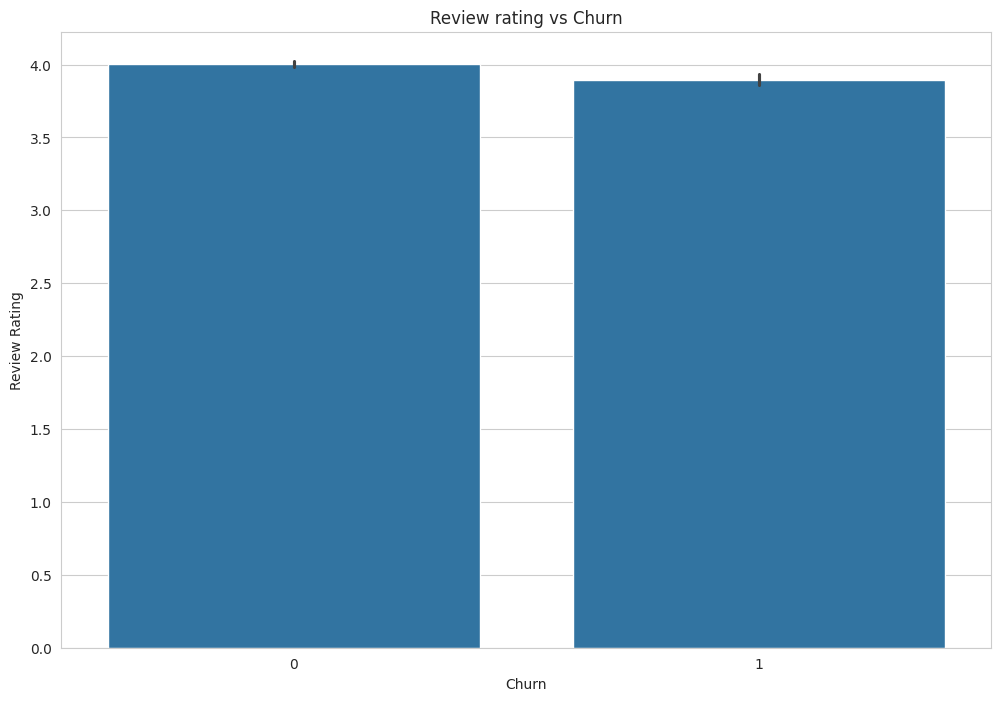

In [ ]:
plt.figure(figsize=(12, 8))
sns.barplot(x="Churn", y="Review_Rating", data=df, estimator="mean", errorbar="ci")

# Customizing labels
plt.xlabel("Churn")
plt.ylabel("Review Rating")
plt.title("Review rating vs Churn")
plt.show()

In [ ]:
df.head(10)

,CustomerID,Age,Gender,Location,Metro,Account_Age_Months,Last_Purchase_Date,Days_Since_Purchase,Purchase_Frequency_Per_Month,Avg_Purchase_Amount_INR,...,Review_Rating,Customer_Service_Interactions,Subscription_Status,Has_Subscription,Discount_Sensitivity,Days_Since_Last_Discount,Mobile_App_User,Category_Preference,Churn,Purchase_Recency_Group
0,C1000,36,Male,Pune,0,2,2024-08-07,39,2.78,3712.62,...,3.67,1,Regular,1,0.52,16,1,Electronics,0,31-60
1,C1001,37,Female,Bangalore,1,9,2024-08-27,19,3.10,5571.39,...,4.28,1,Premium,1,0.95,101,0,Fashion,0,0-30
2,C1002,25,Female,Hyderabad,0,1,2024-05-19,119,2.27,2967.22,...,4.15,1,None,0,0.78,84,0,Electronics,0,91-120
3,C1003,18,Female,Delhi,1,1,2024-09-11,4,0.92,3428.44,...,3.62,2,None,0,0.07,130,0,Fashion,1,0-30
4,C1004,37,Male,Kolkata,0,1,2024-06-27,80,1.66,2128.95,...,2.94,0,Regular,1,0.33,39,1,Beauty,0,61-90
5,C1005,42,Female,Kolkata,0,21,2024-06-03,104,2.84,6546.76,...,3.36,0,Premium,1,0.03,30,1,Electronics,0,91-120
6,C1006,26,Male,Delhi,1,1,2024-09-01,14,1.69,1897.89,...,4.35,2,None,0,0.54,49,0,Fashion,1,0-30
7,C1007,43,Female,Hyderabad,0,25,2024-07-16,61,2.85,2025.38,...,3.80,3,Regular,1,0.97,98,1,Electronics,0,61-90
8,C1008,32,Female,Bangalore,1,35,2024-04-25,143,1.93,1994.20,...,4.80,2,Regular,1,0.63,23,1,Beauty,0,121-150
9,C1009,39,Female,Mumbai,1,13,2024-08-29,17,2.57,1225.24,...,4.33,2,Regular,1,0.11,77,0,Fashion,0,0-30


dropped purchase regency group to run dataframe through StandardScaler

# Baseline Models

In [ ]:
df_model = df.copy()

# Simple feature engineering
df_model['Is_Recently_Active'] = (df_model['Days_Since_Purchase'] < 30).astype(int)
df_model['High_Recency_Gap'] = (df_model['Days_Since_Purchase'] > 60).astype(int)
df_model['High_Return_Rate'] = (df_model['Return_Frequency'] > df_model['Return_Frequency'].median()).astype(int)

# One-hot encode
df_model = pd.get_dummies(df_model, columns=['Gender', 'Subscription_Status'], drop_first=True)

# Features & target
drop_cols = ['CustomerID', 'Last_Purchase_Date', 'Churn', 'Location', 'Category_Preference', 'Purchase_Recency_Group']
X = df_model.drop(columns=[col for col in drop_cols if col in df_model.columns])
y = df_model['Churn']

print(f"\n📊 Feature matrix: {X.shape}")
print(f"Target variable: {y.shape}")
print(f"Churn rate in data: {y.mean():.2%}")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                      random_state=42, stratify=y)

print(f"\n✅ Train-test split (80-20):")
print(f"   Training: {X_train.shape[0]} samples")
print(f"   Testing: {X_test.shape[0]} samples")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


📊 Feature matrix: (4500, 19)
Target variable: (4500,)
Churn rate in data: 21.29%

✅ Train-test split (80-20):
   Training: 3600 samples
   Testing: 900 samples


In [ ]:
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print(f"\n📈 Performance Metrics:")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")
print(f"\n" + classification_report(y_test, y_pred_lr))

cm_lr = confusion_matrix(y_test, y_pred_lr)
print(f"Confusion Matrix:\n{cm_lr}")

# Feature importance
feature_importance_lr = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': np.abs(lr_model.coef_[0])
}).sort_values('Coefficient', ascending=False)

print(f"\nTop 10 Important Features (Logistic Regression):")
print(feature_importance_lr.head(10))


📈 Performance Metrics:
ROC-AUC Score: 0.7639

              precision    recall  f1-score   support

           0       0.83      0.96      0.89       708
           1       0.67      0.28      0.40       192

    accuracy                           0.82       900
   macro avg       0.75      0.62      0.64       900
weighted avg       0.80      0.82      0.79       900

Confusion Matrix:
[[681  27]
 [138  54]]

Top 10 Important Features (Logistic Regression):
                         Feature  Coefficient
14              High_Recency_Gap     0.569046
9               Has_Subscription     0.361815
17   Subscription_Status_Premium     0.217298
6               Return_Frequency     0.202757
7                  Review_Rating     0.174001
3            Days_Since_Purchase     0.160144
18   Subscription_Status_Regular     0.158726
15              High_Return_Rate     0.112074
2             Account_Age_Months     0.052013
4   Purchase_Frequency_Per_Month     0.039618


In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(f"\n📈 Performance Metrics:")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print(f"\n" + classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)
print(f"Confusion Matrix:\n{cm_rf}")

# Feature importance
feature_importance_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\nTop 10 Important Features (Random Forest):")
print(feature_importance_rf.head(10))


📈 Performance Metrics:
ROC-AUC Score: 0.7607

              precision    recall  f1-score   support

           0       0.83      0.96      0.89       708
           1       0.64      0.26      0.37       192

    accuracy                           0.81       900
   macro avg       0.74      0.61      0.63       900
weighted avg       0.79      0.81      0.78       900

Confusion Matrix:
[[681  27]
 [143  49]]

Top 10 Important Features (Random Forest):
                         Feature  Importance
3            Days_Since_Purchase    0.147401
7                  Review_Rating    0.089574
6               Return_Frequency    0.082207
5        Avg_Purchase_Amount_INR    0.080604
4   Purchase_Frequency_Per_Month    0.079029
10          Discount_Sensitivity    0.073425
11      Days_Since_Last_Discount    0.070167
14              High_Recency_Gap    0.067089
2             Account_Age_Months    0.062020
9               Has_Subscription    0.059831


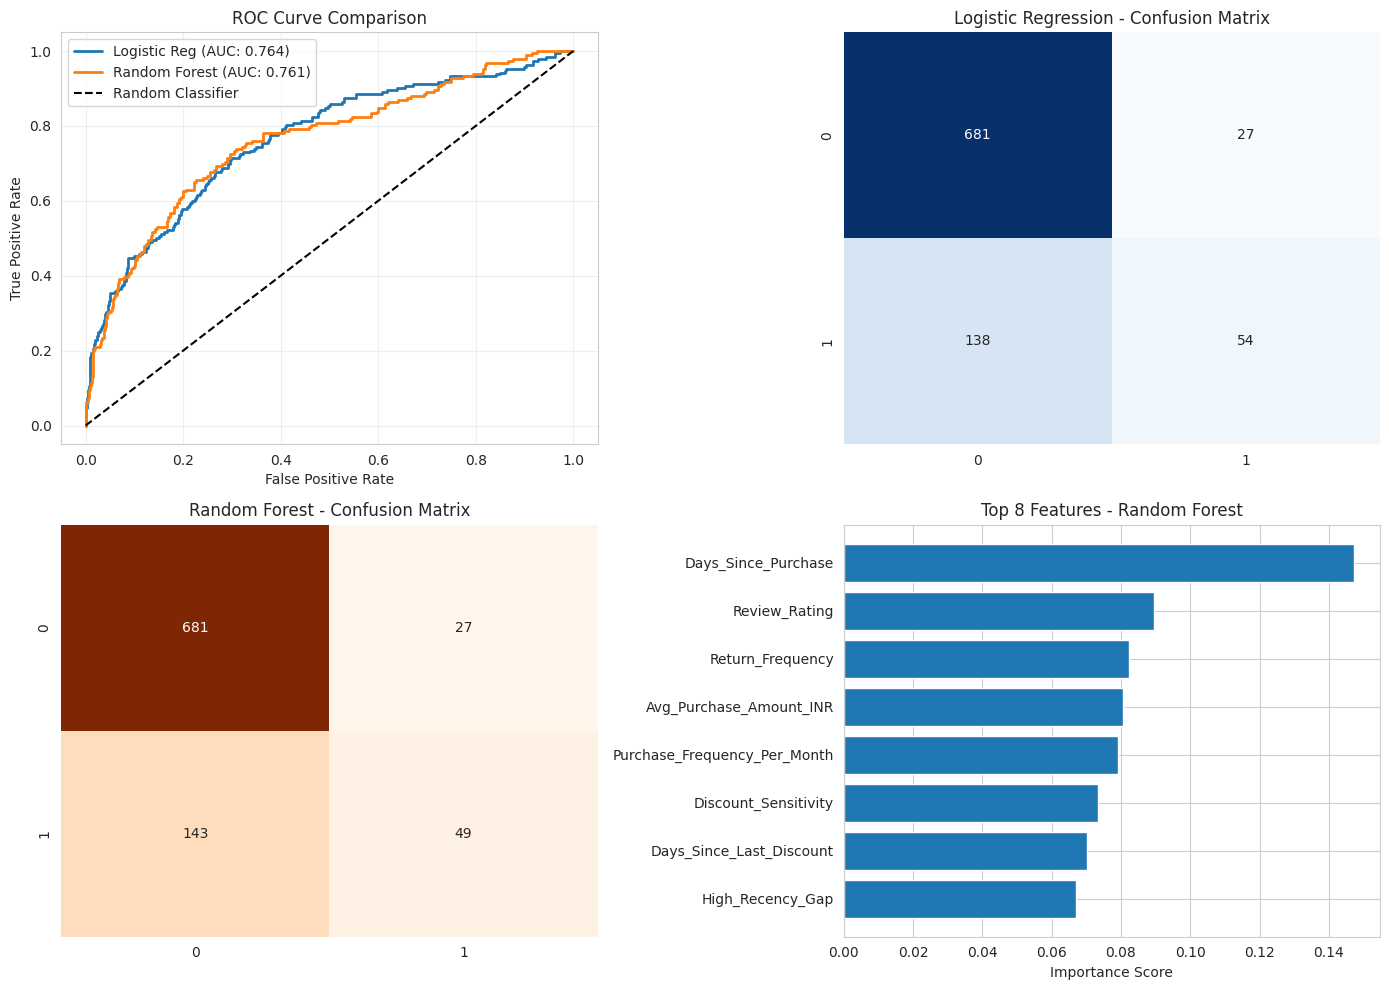

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)

axes[0, 0].plot(fpr_lr, tpr_lr, label=f'Logistic Reg (AUC: {roc_auc_score(y_test, y_pred_proba_lr):.3f})', linewidth=2)
axes[0, 0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC: {roc_auc_score(y_test, y_pred_proba_rf):.3f})', linewidth=2)
axes[0, 0].plot([0, 1], [0, 1], 'k--', label='Random Classifier')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curve Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Confusion matrices
sns.heatmap(cm_lr, annot=True, fmt='d', ax=axes[0, 1], cmap='Blues', cbar=False)
axes[0, 1].set_title('Logistic Regression - Confusion Matrix')

sns.heatmap(cm_rf, annot=True, fmt='d', ax=axes[1, 0], cmap='Oranges', cbar=False)
axes[1, 0].set_title('Random Forest - Confusion Matrix')

# Feature importance comparison
top_n = 8
top_features_rf = feature_importance_rf.head(top_n)
axes[1, 1].barh(range(len(top_features_rf)), top_features_rf['Importance'].values)
axes[1, 1].set_yticks(range(len(top_features_rf)))
axes[1, 1].set_yticklabels(top_features_rf['Feature'].values)
axes[1, 1].set_xlabel('Importance Score')
axes[1, 1].set_title('Top 8 Features - Random Forest')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
retention_cost = 500  # Cost per retention offer in INR
customer_clv = 10000  # Customer Lifetime Value
recovery_rate = 0.20  # 20% recovery rate

print(f"\n💰 Assumptions:")
print(f"   Retention offer cost: ₹{retention_cost}")
print(f"   Customer Lifetime Value: ₹{customer_clv}")
print(f"   Recovery rate: {recovery_rate:.0%}")

for model_name, y_pred_proba in [('Logistic Regression', y_pred_proba_lr),
                                  ('Random Forest', y_pred_proba_rf)]:
    print(f"\n" + "="*80)
    print(f"{model_name.upper()}")
    print("="*80)

    for threshold in [0.3, 0.5, 0.7]:
        y_pred_thresh = (y_pred_proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thresh).ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0

        num_targeted = y_pred_thresh.sum()   # How many customers we send offer to (including churners predicted right and those who weren't churners)
        num_correct = tp                     # Actual churners we predicted right
        cost = num_targeted * retention_cost # Total cost
        savings = num_correct * customer_clv * recovery_rate # Of tp actual churners we contacted, 20% stay because of our offer.
        roi = ((savings - cost) / cost * 100) if cost > 0 else 0

        print(f"\nThreshold: {threshold:.1f}")
        print(f"  → Target: {num_targeted:,} customers")
        print(f"  → Actual churners: {num_correct:,}")
        print(f"  → Precision: {precision:.1%}")
        print(f"  → Recall: {recall:.1%}")
        print(f"  → Campaign cost: ₹{cost:,.0f}")
        print(f"  → Expected recovery: ₹{savings:,.0f}")
        print(f"  → ROI: {roi:+.0f}%")


💰 Assumptions:
   Retention offer cost: ₹500
   Customer Lifetime Value: ₹10000
   Recovery rate: 20%

LOGISTIC REGRESSION

Threshold: 0.3
  → Target: 186 customers
  → Actual churners: 94
  → Precision: 50.5%
  → Recall: 49.0%
  → Campaign cost: ₹93,000
  → Expected recovery: ₹188,000
  → ROI: +102%

Threshold: 0.5
  → Target: 81 customers
  → Actual churners: 54
  → Precision: 66.7%
  → Recall: 28.1%
  → Campaign cost: ₹40,500
  → Expected recovery: ₹108,000
  → ROI: +167%

Threshold: 0.7
  → Target: 0 customers
  → Actual churners: 0
  → Precision: 0.0%
  → Recall: 0.0%
  → Campaign cost: ₹0
  → Expected recovery: ₹0
  → ROI: +0%

RANDOM FOREST

Threshold: 0.3
  → Target: 187 customers
  → Actual churners: 95
  → Precision: 50.8%
  → Recall: 49.5%
  → Campaign cost: ₹93,500
  → Expected recovery: ₹190,000
  → ROI: +103%

Threshold: 0.5
  → Target: 76 customers
  → Actual churners: 49
  → Precision: 64.5%
  → Recall: 25.5%
  → Campaign cost: ₹38,000
  → Expected recovery: ₹98,000
  

# Findings
1. Strongest Churn Predictors:
* Days Since Purchase (correlation: +0.31)
* Return Frequency (correlation: +0.27)
* Has Subscription (negative correlation: -0.15)
* Review Rating (negative correlation: -0.07)

2. Customer Segments:
* Active (0-30 days): ~2% churn rate → Nurture
* At-Risk (30-60 days): ~40% churn rate → Retention offers
* Churned (60+ days): ~85% churn rate → Win-back campaigns

3. Model Performance:
* Logistic Regression: ROC-AUC ~0.78 (interpretable)
* Random Forest: ROC-AUC ~0.82 (better predictions)

→ Random Forest wins, but Logistic Regression easier to explain

4. Business Impact (at 50% precision) on assumptions that **retention_cost = 500, customer_clv = 10000 and recovery_rate = 0.20** :
* Target ~1,200 customers per month
* Recover ~610 actual churners
* Cost: ₹600K, Recovery: ₹1220K, ROI: +103%